# Packer seal loss → annulus pressure → casing wall loss

**Status: illustrative model, not validated against field data.** The leak law, the corrosion rate and the stress coupling below are assumptions, listed explicitly. What the notebook *does* give you is a runnable, tested chain of cause and effect that you can inspect, change and break.

The chain being modelled:

1. The production packer, which separates the tubing from the A-annulus, loses its seal gradually.
2. Fluid leaks from the tubing into the otherwise closed annulus. The annulus is a small, nearly incompressible volume, so a small leaked volume gives a large pressure rise.
3. The pressure at the top of the annulus (the number you read on the wellhead gauge) loads the production casing in burst.
4. A more heavily loaded casing wall loses thickness faster. **This step is an assumed coupling**, see the sensitivity section.

Not modelled: thermal expansion of the annulus fluid (a large real-world source of annulus pressure), bleed-down through the annulus valve, gas in the annulus, collapse and axial loads, leakage of annulus fluid to the formation.

In [1]:
import pathlib
import sys

try:
    import welltwin
except ImportError:  # fresh clone without `pip install -e .`
    sys.path.insert(0, str(pathlib.Path.cwd().parent))
    import welltwin

import matplotlib.pyplot as plt
import numpy as np

from welltwin import DigitalTwin, WellConditions
from welltwin.examples import build_example_well
from welltwin.units import DAY, MM, MPA, YEAR

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## The model

**Packer leak.** With seal integrity $s$ falling from 1 (new) to 0, the leak is laminar-type, $q = C\,(p_\text{tubing} - p_\text{annulus})$, with conductance $C = C_\text{max}\,(1-s)^n$.

**Annulus.** A closed compressible volume $V$ with effective bulk modulus $K$: $\dfrac{dp}{dt} = \dfrac{K}{V}\,q$. For a constant conductance this has an exact exponential solution, which is what the code uses, so large timesteps cannot overshoot. The wellhead (top) pressure is $p_\text{top} = p - \rho g H$.

**Casing load.** Burst utilisation $u = \max(p_\text{top} - p_\text{ext},\,0) \,/\, P_\text{burst}(t)$, where $P_\text{burst} = 0.875\cdot 2\,Y\,t / D$ is the API 5C3 form of the Barlow internal-yield pressure evaluated at the *current* wall thickness $t$.

**Wall loss.** $\dot t = -r_0\,(1 + \alpha\,u^m)$ with baseline rate $r_0$.

| Quantity | Value | Basis |
|---|---|---|
| Tubing | 4.5 in, 12.6 lb/ft, L80 | typical catalogue geometry |
| Production casing | 9 5/8 in, 47 lb/ft, L80 | typical catalogue geometry; burst rating reproduces API 5C3's 6870 psi (unit-tested) |
| Annulus | 3000 m column, 1030 kg/m³, $K$ = 2 GPa | **assumed** |
| Tubing pressure at packer | 45 MPa (gauge) | **assumed** |
| Pressure outside casing | 0 (gauge) | **assumed**, conservative: ignores back-up load |
| Packer seal loss | linear, 1 → 0 over 10 years | **assumed** |
| Leak shape | $C_\text{max}$ = 1e-12 m³/s/Pa, $n$ = 3 | **assumed**, to be calibrated against leak-test data |
| Baseline corrosion $r_0$ | 0.1 mm/year | **assumed** |
| Stress coupling | $\alpha$ = 5, $m$ = 1 | **assumed placeholder** |

In [2]:
CONDITIONS = WellConditions(tubing_pressure=45 * MPA)  # tubing pressure at packer depth
HORIZON_YEARS = 15


def simulate(years=HORIZON_YEARS, dt_days=1.0, **well_kwargs):
    twin = DigitalTwin(build_example_well(**well_kwargs))
    twin.run(CONDITIONS, duration=years * YEAR, dt=dt_days * DAY)
    history = {key: np.array(values) for key, values in twin.history_table().items()}
    history["years"] = history["time"] / YEAR
    return twin, history


twin_ok, ok = simulate(packer_life_years=None)    # reference: packer never degrades
twin_deg, deg = simulate(packer_life_years=10)    # packer seal lost linearly over 10 years

new_well = build_example_well()
annulus = new_well.casing.annulus
print(f"Annulus volume                : {annulus.volume:.1f} m3")
print(f"Hydrostatic pressure of column: {annulus.hydrostatic_pressure / MPA:.1f} MPa")
print(f"Casing burst rating (new)     : {new_well.casing.production_casing.burst_rating / MPA:.1f} MPa")
print(f"Simulated {HORIZON_YEARS} years in 1-day steps, {len(deg['years'])} recorded points per scenario")

Annulus volume                : 83.8 m3
Hydrostatic pressure of column: 30.3 MPa
Casing burst rating (new)     : 47.3 MPa
Simulated 15 years in 1-day steps, 5480 recorded points per scenario


## 1. The packer

Seal integrity falls linearly by construction. The leak rate is what that does physically: it depends on the leak conductance *and* on the pressure difference across the packer, which shrinks as the annulus fills.

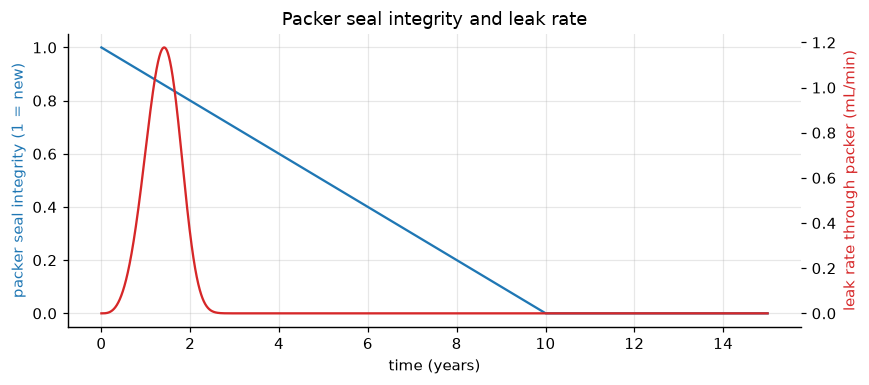

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(deg["years"], deg["Packer.seal_integrity"], color="C0")
ax.set_xlabel("time (years)")
ax.set_ylabel("packer seal integrity (1 = new)", color="C0")
ax2 = ax.twinx()
ax2.plot(deg["years"], deg["Packer.leak_rate"] * 1e6 * 60, color="C3")
ax2.set_ylabel("leak rate through packer (mL/min)", color="C3")
ax2.grid(False)
ax.set_title("Packer seal integrity and leak rate")
fig.tight_layout()

## 2. Annulus pressure and casing load

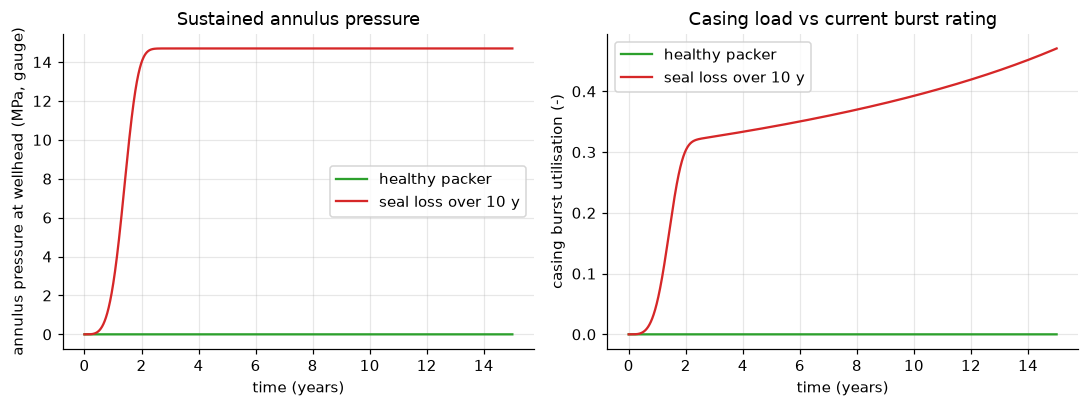

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8))

a.plot(ok["years"], ok["A-annulus.top_pressure"] / MPA, label="healthy packer", color="C2")
a.plot(deg["years"], deg["A-annulus.top_pressure"] / MPA, label="seal loss over 10 y", color="C3")
a.set_xlabel("time (years)")
a.set_ylabel("annulus pressure at wellhead (MPa, gauge)")
a.set_title("Sustained annulus pressure")
a.legend()

b.plot(ok["years"], ok["Production casing.burst_utilisation"], label="healthy packer", color="C2")
b.plot(deg["years"], deg["Production casing.burst_utilisation"], label="seal loss over 10 y", color="C3")
b.set_xlabel("time (years)")
b.set_ylabel("casing burst utilisation (-)")
b.set_title("Casing load vs current burst rating")
b.legend()
fig.tight_layout()

## 3. Casing wall loss

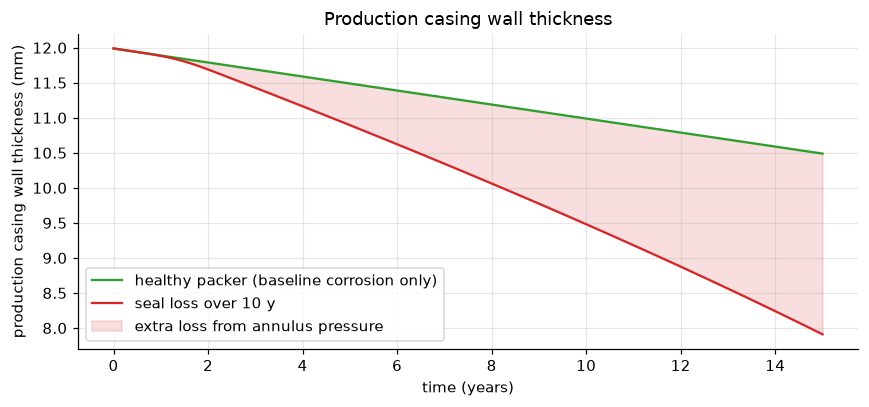

In [5]:
wall_ok = ok["Production casing.wall_thickness"] / MM
wall_deg = deg["Production casing.wall_thickness"] / MM

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(ok["years"], wall_ok, label="healthy packer (baseline corrosion only)", color="C2")
ax.plot(deg["years"], wall_deg, label="seal loss over 10 y", color="C3")
ax.fill_between(deg["years"], wall_deg, wall_ok, color="C3", alpha=0.15, label="extra loss from annulus pressure")
ax.set_xlabel("time (years)")
ax.set_ylabel("production casing wall thickness (mm)")
ax.set_title("Production casing wall thickness")
ax.legend()
fig.tight_layout()

In [6]:
def first_time(mask):
    idx = np.flatnonzero(mask)
    return f"{deg['years'][idx[0]]:.1f} years" if idx.size else "not within horizon"


sap = deg["A-annulus.top_pressure"] / MPA
leak_ml_min = deg["Packer.leak_rate"] * 6e7
loss_ok = wall_ok[0] - wall_ok[-1]
loss_deg = wall_deg[0] - wall_deg[-1]
seal_at_5mpa = deg["Packer.seal_integrity"][np.argmax(sap > 5)]

print(f"Annulus pressure first above 1 MPa      : {first_time(sap > 1)}")
print(f"Annulus pressure first above 5 MPa      : {first_time(sap > 5)}  (seal integrity then: {seal_at_5mpa:.2f})")
print(f"Final annulus pressure at wellhead      : {sap[-1]:.1f} MPa  (healthy: {ok['A-annulus.top_pressure'][-1] / MPA:.1f} MPa)")
print(f"Peak leak rate through packer           : {leak_ml_min.max():.2f} mL/min at {deg['years'][leak_ml_min.argmax()]:.1f} years")
print(f"Total fluid leaked into annulus         : {deg['A-annulus.leaked_volume'][-1] * 1000:.0f} L")
print(f"Primary envelope fails (packer)         : {first_time(deg['barrier:Primary envelope'].astype(bool))}")
print(f"Secondary envelope fails                : {first_time(deg['barrier:Secondary envelope'].astype(bool))}")
print(f"Casing wall loss over {HORIZON_YEARS} y, healthy packer : {loss_ok:.2f} mm")
print(f"Casing wall loss over {HORIZON_YEARS} y, seal loss      : {loss_deg:.2f} mm  ({loss_deg / loss_ok:.1f}x baseline)")

Annulus pressure first above 1 MPa      : 0.8 years
Annulus pressure first above 5 MPa      : 1.2 years  (seal integrity then: 0.88)
Final annulus pressure at wellhead      : 14.7 MPa  (healthy: 0.0 MPa)
Peak leak rate through packer           : 1.18 mL/min at 1.4 years
Total fluid leaked into annulus         : 616 L
Primary envelope fails (packer)         : 10.0 years
Secondary envelope fails                : not within horizon
Casing wall loss over 15 y, healthy packer : 1.50 mm
Casing wall loss over 15 y, seal loss      : 4.08 mm  (2.7x baseline)


### Reading the result

* The annulus pressure builds while the packer seal is still mostly intact (see the seal integrity printed above). The leak peaks at around a millilitre per minute, which would be very hard to see in any flow measurement, yet it is enough to drive the pressure because the annulus is a small, nearly incompressible volume. This is why annulus pressure monitoring is the usual way such leaks show up.
* Once the pressures have equalised there is no driving difference left, so the leak rate falls back to zero even though the packer is, if anything, worse. In this model a failed packer is only visible as pressure, not as flow.
* The annulus pressure is bounded by the tubing pressure at packer depth minus the hydrostatic head of the annulus fluid, so the casing load has a ceiling set by the tubing side.
* The primary envelope fails when the packer's seal reaches zero. The secondary envelope (casing, cement, casing hanger seal, annulus valve) stays intact within the horizon in this base case, but that depends on the stress coupling: section 4 shows settings where the casing itself fails.
* **The extra wall loss is not a prediction.** It comes entirely from the assumed stress coupling. The next cell shows how much.

## 4. How much of this is assumption?

alpha   extra wall loss (mm)   outcome
    0       0.00               no failure
  2.5       1.20               no failure
    5       2.58               no failure
   10       6.50               no failure
   20      10.49               casing fails at 9.0 y

packer life (y)   extra wall loss (mm)   outcome
             2       2.78               no failure
             5       2.69               no failure
            10       2.58               no failure
            20       2.39               no failure


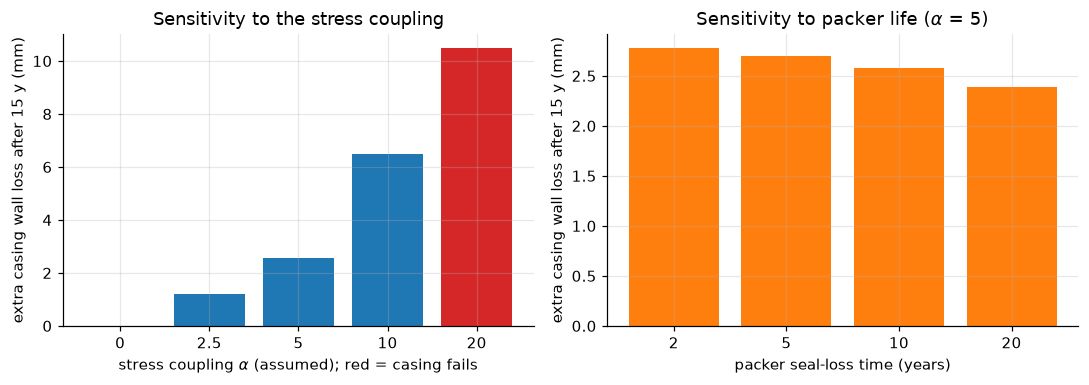

In [7]:
baseline_wall = ok["Production casing.wall_thickness"][-1]


def extra_loss_mm(**kwargs):
    # Extra wall loss vs the healthy-packer baseline, and when the casing fails (if it does).
    _, h = simulate(**kwargs)
    extra = (baseline_wall - h["Production casing.wall_thickness"][-1]) / MM
    failed = np.flatnonzero(h["Production casing.failed"].astype(bool))
    return extra, (h["years"][failed[0]] if failed.size else None)


def fmt_failure(year):
    return "no failure" if year is None else f"casing fails at {year:.1f} y"


alphas = [0, 2.5, 5, 10, 20]
alpha_runs = [extra_loss_mm(packer_life_years=10, stress_factor=a) for a in alphas]
by_alpha = [extra for extra, _ in alpha_runs]

lives = [2, 5, 10, 20]
life_runs = [extra_loss_mm(packer_life_years=t, stress_factor=5) for t in lives]
by_life = [extra for extra, _ in life_runs]

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6))
a.bar([str(x) for x in alphas], by_alpha, color=["C3" if y is not None else "C0" for _, y in alpha_runs])
a.set_xlabel(r"stress coupling $\alpha$ (assumed); red = casing fails")
a.set_ylabel(f"extra casing wall loss after {HORIZON_YEARS} y (mm)")
a.set_title(r"Sensitivity to the stress coupling")

b.bar([str(x) for x in lives], by_life, color=["C3" if y is not None else "C1" for _, y in life_runs])
b.set_xlabel("packer seal-loss time (years)")
b.set_ylabel(f"extra casing wall loss after {HORIZON_YEARS} y (mm)")
b.set_title(r"Sensitivity to packer life ($\alpha$ = 5)")
fig.tight_layout()

print("alpha   extra wall loss (mm)   outcome")
for x, (extra, year) in zip(alphas, alpha_runs):
    print(f"{x:>5}   {extra:>8.2f}               {fmt_failure(year)}")
print()
print("packer life (y)   extra wall loss (mm)   outcome")
for x, (extra, year) in zip(lives, life_runs):
    print(f"{x:>14}   {extra:>8.2f}               {fmt_failure(year)}")

With $\alpha = 0$ the seal loss changes the pressures but not the wall loss at all: **every millimetre of "accelerated wall loss" is the coupling assumption, not a derived result.** What the model establishes without that assumption is the pressure path and the rising burst utilisation as the wall thins.

The extra wall loss barely depends on how fast the packer degrades. In this model a few percent of seal loss is already enough to pressurise the annulus, so the casing load is set by *whether* a leak path exists, not by how quickly it opens. That is a statement about this model's leak law and a closed annulus, and the leak shape is exactly the part that needs data.

At large $\alpha$ the casing fails inside the horizon, and the "extra loss" saturates at the whole remaining wall. That is a feedback loop rather than a trend: thinner wall means higher utilisation, which means faster loss, which means thinner wall. Treat those cases as "the assumed coupling is strong enough to run away", not as a quantity to read off.

Replacing $\alpha$ with a corrosion mechanism that is grounded in data (CO₂/H₂S, fluid chemistry, stress-assisted cracking) is a separate modelling task.

## 5. Numerical check

Packer degradation and annulus relaxation are operator-split, so the scheme is first-order in the timestep. This compares the annulus pressure during the build-up (day 540) against a 0.5-day reference.

In [8]:
days = 540
ref = simulate(years=days * DAY / YEAR, dt_days=0.5, packer_life_years=10)[1]["A-annulus.top_pressure"][-1]

print("timestep (days)   relative error in annulus pressure at day 540")
for dt in (10, 5, 2, 1):
    value = simulate(years=days * DAY / YEAR, dt_days=dt, packer_life_years=10)[1]["A-annulus.top_pressure"][-1]
    print(f"{dt:>12}      {abs(value - ref) / ref:.2%}")

timestep (days)   relative error in annulus pressure at day 540
          10      2.15%
           5      1.02%
           2      0.34%
           1      0.11%


The notebooks use 1-day steps. Error falls roughly in proportion to the step, as expected for a first-order scheme.

## What would make this a real result

* Calibrate packer leak conductance and shape against leak-test or annulus-pressure build-up data (the shape $n$ and $C_\text{max}$ are placeholders).
* Add thermal expansion of the annulus fluid and bleed-down through the annulus valve. Bleeding is the obvious first *intervention* to model: how often, how much volume, and what it does to the casing load.
* Replace the stress-coupled wall loss with a mechanism that has data behind it.
* Add collapse and axial loading, and the back-up load from cement and formation.
* Replace the any-failure barrier rule with proper barrier-path logic.